In [2]:
import os
import csv
import json
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, cohen_kappa_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Load Day 4 patches
npz_path = "/content/drive/MyDrive/TerraSpectra/data/patches/terraspectra_patches.npz"
data = np.load(npz_path)

class HyperspectralPatchDataset(Dataset):
    def __init__(self, X, y, augment=False):
        # X input shape: (N, 15, 15, 30) -> convert to (N, 1, 30, 15, 15)
        X_t = np.transpose(X, (0, 3, 1, 2))
        self.X = torch.tensor(np.expand_dims(X_t, axis=1), dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
        self.augment = augment

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        patch = self.X[idx]  # Shape: (1, 30, 15, 15)
        if self.augment:
            # Random Horizontal Flip (width axis = -1)
            if torch.rand(1).item() > 0.5:
                patch = torch.flip(patch, dims=[-1])
            # Random Vertical Flip (height axis = -2)
            if torch.rand(1).item() > 0.5:
                patch = torch.flip(patch, dims=[-2])
            # Random 0, 90, 180, or 270 degree spatial rotation
            k = torch.randint(0, 4, (1,)).item()
            if k > 0:
                patch = torch.rot90(patch, k=k, dims=[-2, -1])
        return patch, self.y[idx]

train_loader = DataLoader(HyperspectralPatchDataset(data["X_train"], data["y_train"], augment=True), batch_size=64, shuffle=True)
val_loader   = DataLoader(HyperspectralPatchDataset(data["X_val"],   data["y_val"],   augment=False), batch_size=64, shuffle=False)
test_loader  = DataLoader(HyperspectralPatchDataset(data["X_test"],  data["y_test"],  augment=False), batch_size=64, shuffle=False)

num_classes = len(np.unique(data["y_train"]))
print(f"Augmented Train Dataset Ready! Samples: {len(data['y_train'])} | Classes: {num_classes}")

Using device: cuda
Augmented Train Dataset Ready! Samples: 7174 | Classes: 16


In [3]:
class Spectral3DViTFusion(nn.Module):
    def __init__(self, num_classes=16, embed_dim=128, num_heads=4, num_layers=2, dropout=0.2):
        super().__init__()
        self.conv3d = nn.Sequential(
            nn.Conv3d(1, 8, kernel_size=(7, 3, 3)),
            nn.BatchNorm3d(8),
            nn.GELU(),
            nn.Conv3d(8, 16, kernel_size=(5, 3, 3)),
            nn.BatchNorm3d(16),
            nn.GELU(),
            nn.Conv3d(16, 32, kernel_size=(3, 3, 3)),
            nn.BatchNorm3d(32),
            nn.GELU(),
        )
        num_tokens = 9 * 9
        self.token_proj = nn.Linear(32 * 18, embed_dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.randn(1, num_tokens + 1, embed_dim) * 0.02)
        self.pos_drop = nn.Dropout(dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 2,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Sequential(
            nn.Linear(embed_dim, 64),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.conv3d(x)
        b, c, d, h, w = x.shape
        x = x.view(b, c * d, h * w).transpose(1, 2)
        x = self.token_proj(x)
        cls_tokens = self.cls_token.expand(b, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)
        x = self.pos_drop(x + self.pos_embed)
        x = self.transformer(x)
        return self.head(self.norm(x[:, 0]))

model = Spectral3DViTFusion(num_classes=num_classes).to(device)
print("Tuned 3D-CNN + ViT Model Initialized!")

Tuned 3D-CNN + ViT Model Initialized!


/tmp/ipykernel_749/1570672081.py:30: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


Epoch 01/60 | Train Loss: 1.0196 Acc: 78.25% | Val Loss: 0.4910 Acc: 94.80% | LR: 0.001000
Epoch 05/60 | Train Loss: 0.3843 Acc: 98.73% | Val Loss: 0.3569 Acc: 98.70% | LR: 0.000989
Epoch 10/60 | Train Loss: 0.3543 Acc: 99.50% | Val Loss: 0.3566 Acc: 98.96% | LR: 0.000946
Epoch 15/60 | Train Loss: 0.3526 Acc: 99.46% | Val Loss: 0.3306 Acc: 99.80% | LR: 0.000873
Epoch 20/60 | Train Loss: 0.3455 Acc: 99.65% | Val Loss: 0.3391 Acc: 99.41% | LR: 0.000775
Epoch 25/60 | Train Loss: 0.3339 Acc: 99.92% | Val Loss: 0.3311 Acc: 99.80% | LR: 0.000658
Epoch 30/60 | Train Loss: 0.3334 Acc: 99.92% | Val Loss: 0.3286 Acc: 99.87% | LR: 0.000531
Epoch 35/60 | Train Loss: 0.3315 Acc: 99.97% | Val Loss: 0.3263 Acc: 99.87% | LR: 0.000402
Epoch 40/60 | Train Loss: 0.3296 Acc: 99.99% | Val Loss: 0.3222 Acc: 99.93% | LR: 0.000280
Epoch 45/60 | Train Loss: 0.3298 Acc: 99.94% | Val Loss: 0.3211 Acc: 100.00% | LR: 0.000174
Epoch 50/60 | Train Loss: 0.3289 Acc: 100.00% | Val Loss: 0.3211 Acc: 100.00% | LR: 0.000

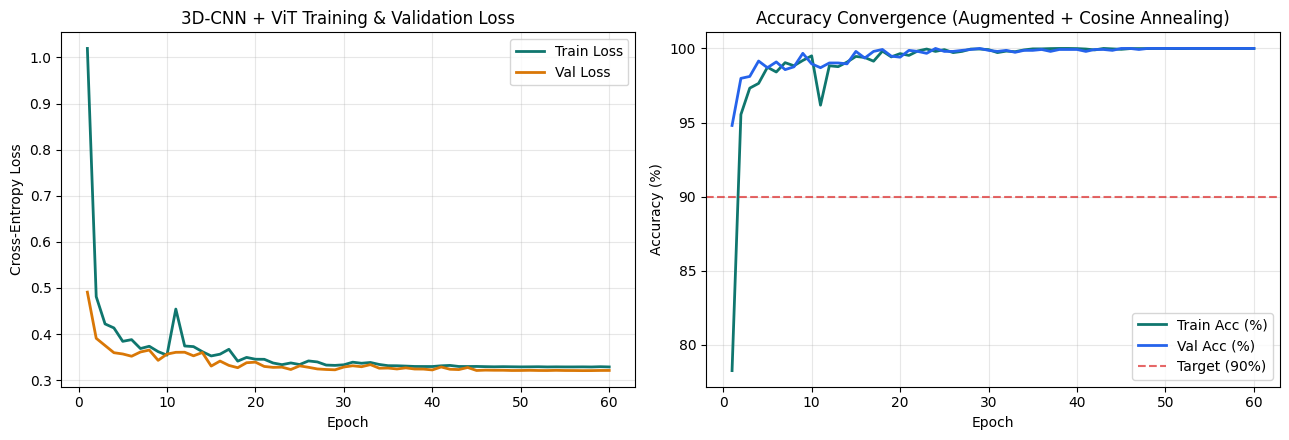


=== DAY 8 TUNED TEST RESULTS (214.1s) ===
Test Overall Accuracy (OA): 99.80%
Cohen's Kappa Score:        0.9978
Saved logs -> /content/drive/MyDrive/TerraSpectra/data/artifacts/training_logs_day8.csv
Saved plot -> /content/drive/MyDrive/TerraSpectra/data/artifacts/training_curves_day8.png


In [4]:
SAVE_DIR = "/content/drive/MyDrive/TerraSpectra/data/artifacts"
os.makedirs(SAVE_DIR, exist_ok=True)

MODEL_PATH  = f"{SAVE_DIR}/vit_fusion_tuned_day8.pth"
LOG_CSV     = f"{SAVE_DIR}/training_logs_day8.csv"
CURVE_PNG   = f"{SAVE_DIR}/training_curves_day8.png"
METRICS_OUT = f"{SAVE_DIR}/metrics_day8.json"

EPOCHS = 60
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)

history = []
best_val_acc = 0.0
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    # --- Train ---
    model.train()
    t_loss, t_correct, t_total = 0.0, 0, 0
    for X_b, y_b in train_loader:
        X_b, y_b = X_b.to(device), y_b.to(device)
        optimizer.zero_grad()
        out = model(X_b)
        loss = criterion(out, y_b)
        loss.backward()
        optimizer.step()

        t_loss += loss.item() * X_b.size(0)
        t_correct += (out.argmax(1) == y_b).sum().item()
        t_total += y_b.size(0)

    train_loss = t_loss / t_total
    train_acc = (t_correct / t_total) * 100

    # --- Validate ---
    model.eval()
    v_loss, v_correct, v_total = 0.0, 0, 0
    with torch.no_grad():
        for X_b, y_b in val_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            out = model(X_b)
            loss = criterion(out, y_b)
            v_loss += loss.item() * X_b.size(0)
            v_correct += (out.argmax(1) == y_b).sum().item()
            v_total += y_b.size(0)

    val_loss = v_loss / v_total
    val_acc = (v_correct / v_total) * 100
    current_lr = optimizer.param_groups[0]["lr"]
    scheduler.step()

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), MODEL_PATH)

    history.append({
        "epoch": epoch,
        "train_loss": round(train_loss, 5),
        "train_acc": round(train_acc, 2),
        "val_loss": round(val_loss, 5),
        "val_acc": round(val_acc, 2),
        "lr": round(current_lr, 6)
    })

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f} Acc: {val_acc:.2f}% | LR: {current_lr:.6f}")

elapsed = round(time.time() - start_time, 1)

# Save CSV Training Logs
with open(LOG_CSV, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "lr"])
    writer.writeheader()
    writer.writerows(history)

# Plot Loss & Accuracy Curves
epochs_x = [h["epoch"] for h in history]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(epochs_x, [h["train_loss"] for h in history], label="Train Loss", color="#0f766e", linewidth=2)
ax1.plot(epochs_x, [h["val_loss"] for h in history], label="Val Loss", color="#d97706", linewidth=2)
ax1.set_title("3D-CNN + ViT Training & Validation Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Cross-Entropy Loss")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(epochs_x, [h["train_acc"] for h in history], label="Train Acc (%)", color="#0f766e", linewidth=2)
ax2.plot(epochs_x, [h["val_acc"] for h in history], label="Val Acc (%)", color="#2563eb", linewidth=2)
ax2.axhline(90, color="#dc2626", linestyle="--", alpha=0.7, label="Target (90%)")
ax2.set_title("Accuracy Convergence (Augmented + Cosine Annealing)")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.savefig(CURVE_PNG, dpi=150)
plt.show()

# Final Test Evaluation on Tuned Weights
model.load_state_dict(torch.load(MODEL_PATH))
model.eval()
all_preds, all_targets = [], []
with torch.no_grad():
    for X_b, y_b in test_loader:
        X_b = X_b.to(device)
        all_preds.extend(model(X_b).argmax(1).cpu().numpy())
        all_targets.extend(y_b.numpy())

test_oa = accuracy_score(all_targets, all_preds) * 100
kappa = cohen_kappa_score(all_targets, all_preds)

metrics_day8 = {
    "model": "Spectral3DViTFusion (Augmented + CosineAnnealingLR)",
    "epochs": EPOCHS,
    "training_time_sec": elapsed,
    "best_val_acc": round(best_val_acc, 2),
    "test_overall_accuracy": round(test_oa, 2),
    "cohen_kappa": round(float(kappa), 4)
}
with open(METRICS_OUT, "w") as f:
    json.dump(metrics_day8, f, indent=2)

print(f"\n=== DAY 8 TUNED TEST RESULTS ({elapsed}s) ===")
print(f"Test Overall Accuracy (OA): {test_oa:.2f}%")
print(f"Cohen's Kappa Score:        {kappa:.4f}")
print(f"Saved logs -> {LOG_CSV}")
print(f"Saved plot -> {CURVE_PNG}")